<a href="https://colab.research.google.com/github/smartinezdf/cardiometabolic-phenotype-discovery/blob/main/Final_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()
print(uploaded.keys())

Saving AI-PROJECT2.zip to AI-PROJECT2 (1).zip
dict_keys(['AI-PROJECT2 (1).zip'])


> The NHANES dataset is stored in a compressed ZIP file containing multiple survey cycles. Each cycle represents a different time period and includes various health-related measurements. We extract and organize these datasets to prepare them for analysis.


In [ ]:
import zipfile
import os

zip_name = list(uploaded.keys())[0]
zip_path = f"/content/{zip_name}"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Unzipped.")
print("Contents of /content:")
print(os.listdir("/content"))

Unzipped.
Contents of /content:
['.config', 'AI-PROJECT2 (1).zip', 'AI-PROJECT2.zip', 'AI-PROJECT2', 'AI-PROJECT2-20260417T003048Z-3-001.zip', '__MACOSX', 'sample_data']


In [ ]:

from pathlib import Path

base = Path("/content")
PROJECT_DIR = None

# Find the folder that directly contains DATASETS
for folder in base.rglob("DATASETS"):
    PROJECT_DIR = folder.parent
    break

if PROJECT_DIR is None:
    raise FileNotFoundError("Could not find a project folder containing DATASETS.")

DATASETS_DIR = PROJECT_DIR / "DATASETS"
RAW_DIR = DATASETS_DIR / "Separate Datasets"
CARDIO_CSV = DATASETS_DIR / "cardiometabolic_data.csv"

print("PROJECT_DIR:", PROJECT_DIR)
print("DATASETS exists:", DATASETS_DIR.exists())
print("RAW exists:", RAW_DIR.exists())
print("CSV exists:", CARDIO_CSV.exists())

PROJECT_DIR: /content/AI-PROJECT2
DATASETS exists: True
RAW exists: True
CSV exists: True


In [ ]:
!pip install -q pandas pyreadstat scikit-learn matplotlib kneed tensorflow

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from kneed import KneeLocator

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 32.4 MB/s eta 0:00:00


In [ ]:
cycles = ["G", "H", "I", "J"]
file_prefixes = ["DEMO", "GLU", "GHB", "HDL", "TRIGLY", "TCHOL", "BIOPRO", "BPX", "BMX"]

data = {}

for cycle in cycles:
    data[cycle] = {}
    for prefix in file_prefixes:
        file_lower = RAW_DIR / f"{prefix}_{cycle}.xpt"
        file_upper = RAW_DIR / f"{prefix}_{cycle}.XPT"

        file_path = file_lower if file_lower.exists() else file_upper

        if not file_path.exists():
            raise FileNotFoundError(f"Missing file: {prefix}_{cycle}")

        data[cycle][prefix] = pd.read_sas(file_path)
        print(f"Loaded {file_path.name}: {data[cycle][prefix].shape}")

Loaded DEMO_G.xpt: (9756, 48)
Loaded GLU_G.xpt: (3239, 8)
Loaded GHB_G.xpt: (6549, 2)
Loaded HDL_G.xpt: (7821, 3)
Loaded TRIGLY_G.xpt: (3239, 6)
Loaded TCHOL_G.xpt: (7821, 3)
Loaded BIOPRO_G.xpt: (6549, 38)
Loaded BPX_G.xpt: (9338, 27)
Loaded BMX_G.xpt: (9338, 26)
Loaded DEMO_H.xpt: (10175, 47)
Loaded GLU_H.xpt: (3329, 6)
Loaded GHB_H.xpt: (6979, 2)
Loaded HDL_H.xpt: (8291, 3)
Loaded TRIGLY_H.xpt: (3329, 6)
Loaded TCHOL_H.xpt: (8291, 3)
Loaded BIOPRO_H.xpt: (6979, 38)
Loaded BPX_H.xpt: (9813, 23)
Loaded BMX_H.xpt: (9813, 26)
Loaded DEMO_I.xpt: (9971, 47)
Loaded GLU_I.xpt: (3191, 4)
Loaded GHB_I.xpt: (6744, 2)
Loaded HDL_I.xpt: (8021, 3)
Loaded TRIGLY_I.xpt: (3191, 6)
Loaded TCHOL_I.xpt: (8021, 3)
Loaded BIOPRO_I.xpt: (6744, 38)
Loaded BPX_I.xpt: (9544, 21)
Loaded BMX_I.xpt: (9544, 26)
Loaded DEMO_J.xpt: (9254, 46)
Loaded GLU_J.xpt: (3036, 4)
Loaded GHB_J.xpt: (6401, 2)
Loaded HDL_J.xpt: (7435, 3)
Loaded TRIGLY_J.xpt: (3036, 10)
Loaded TCHOL_J.xpt: (7435, 3)
Loaded BIOPRO_J.xpt: (6401, 

>NHANES dataset is divided into cycles and each file represent a specifc type of measurement. We loop through each of those measurements and load them all that are relevant in the dataset


In [ ]:
df_G = data["G"]["DEMO"].merge(data["G"]["GLU"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["GHB"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["HDL"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["TRIGLY"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["TCHOL"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["BIOPRO"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["BPX"], on="SEQN", how="inner")
df_G = df_G.merge(data["G"]["BMX"], on="SEQN", how="inner")

df_H = data["H"]["DEMO"].merge(data["H"]["GLU"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["GHB"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["HDL"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["TRIGLY"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["TCHOL"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["BIOPRO"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["BPX"], on="SEQN", how="inner")
df_H = df_H.merge(data["H"]["BMX"], on="SEQN", how="inner")

df_I = data["I"]["DEMO"].merge(data["I"]["GLU"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["GHB"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["HDL"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["TRIGLY"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["TCHOL"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["BIOPRO"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["BPX"], on="SEQN", how="inner")
df_I = df_I.merge(data["I"]["BMX"], on="SEQN", how="inner")

df_J = data["J"]["DEMO"].merge(data["J"]["GLU"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["GHB"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["HDL"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["TRIGLY"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["TCHOL"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["BIOPRO"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["BPX"], on="SEQN", how="inner")
df_J = df_J.merge(data["J"]["BMX"], on="SEQN", how="inner")

df_G["Cycle"] = "G (2011-2012)"
df_H["Cycle"] = "H (2013-2014)"
df_I["Cycle"] = "I (2015-2016)"
df_J["Cycle"] = "J (2017-2018)"

>Datasets are merged using the unique participant ID (SEQN). This ensures that all measurements correspond to the same individuals.

In [ ]:
df_all = pd.concat([df_G, df_H, df_I, df_J], axis=0, ignore_index=True)

print(df_all.shape)
df_all.head()

(12795, 167)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGY,...,DMDHSEDZ,LBDLDLM,LBDLDMSI,LBDLDLN,LBDLDNSI,LBDSATLC,LBDSGTLC,LBDSTBLC,BMXHIP,BMIHIP
0,62161.0,7.0,2.0,1.0,22.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,62164.0,7.0,2.0,2.0,44.0,NaN,3.0,3.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,62165.0,7.0,2.0,2.0,14.0,NaN,4.0,4.0,2.0,14.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,62169.0,7.0,2.0,1.0,21.0,NaN,5.0,6.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,62170.0,7.0,2.0,1.0,15.0,NaN,5.0,7.0,1.0,15.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We combined multiple NHANES datasets (cycles G through J) into a single dataset using concatenation, stacking them vertically to increase the sample size and improve the robustness of our analysis. This resulted in a dataset with 12,795 observations and 166 variables, capturing a wide range of demographic, clinical, and biomarker information. By merging these cycles, we ensured that our analysis reflects a broader and more representative population over time. However, since not all variables are present in every cycle, this process introduced missing values, which we addressed in later preprocessing steps. This combined dataset serves as the foundation for our dimensionality reduction and clustering analysis.

In [ ]:
selected_cols = [
    "LBXGLU",   # glucose
    "LBXGH",    # HbA1c
    "LBDHDD",   # HDL
    "LBXTR",    # triglycerides
    "LBXTC",    # total cholesterol
    "BMXBMI",   # BMI
    "BPXSY1",   # systolic BP
    "BPXDI1",   # diastolic BP
    "Cycle"
]

features = df_all[selected_cols].copy()
features = features.dropna()

features_ml = features.copy()

print(features.shape)
features.head()

(10616, 9)


,LBXGLU,LBXGH,LBDHDD,LBXTR,LBXTC,BMXBMI,BPXSY1,BPXDI1,Cycle
0,92.0,5.1,41.0,84.0,168.0,23.3,110.0,82.0,G (2011-2012)
1,82.0,4.9,28.0,56.0,190.0,23.2,116.0,56.0,G (2011-2012)
2,88.0,5.9,63.0,71.0,161.0,27.2,110.0,64.0,G (2011-2012)
3,107.0,5.4,43.0,78.0,132.0,20.1,124.0,80.0,G (2011-2012)
4,99.0,5.2,61.0,44.0,147.0,18.2,124.0,82.0,G (2011-2012)


We selected a subset of clinically relevant variables associated with cardiometabolic health, including glucose (LBXGLU), HbA1c (LBXGH), HDL cholesterol (LBDHDD), triglycerides (LBXTR), total cholesterol (LBXTC), body mass index (BMXBMI), and systolic and diastolic blood pressure (BPXSY1, BPXDI1). This selection was made to focus the analysis on meaningful biomarkers while reducing noise from less relevant variables. A new dataset was created using only these features, and observations with missing values were removed to ensure consistency and reliability in the analysis. After this preprocessing step, the final dataset contained 10,616 observations and 8 variables. This cleaned and focused dataset provides a strong foundation for subsequent steps, including data standardization, dimensionality reduction, and clustering.

Before applying PCA, we standardized the selected features using the StandardScaler method to ensure that all variables contribute equally to the analysis. Since the selected variables are measured on different scales (for example, glucose and cholesterol are measured in different units than BMI and blood pressure), features with larger values could dominate the results if left unscaled. Standardization transforms each variable to have a mean of 0 and a standard deviation of 1, removing scale-related bias. This step is especially important for PCA and K-Means, as both methods are sensitive to the magnitude of the data. By standardizing the dataset, we ensured that the analysis captures true patterns in the data rather than differences in measurement units.

In [ ]:
features.to_csv("cardiometabolic_data.csv", index=False)

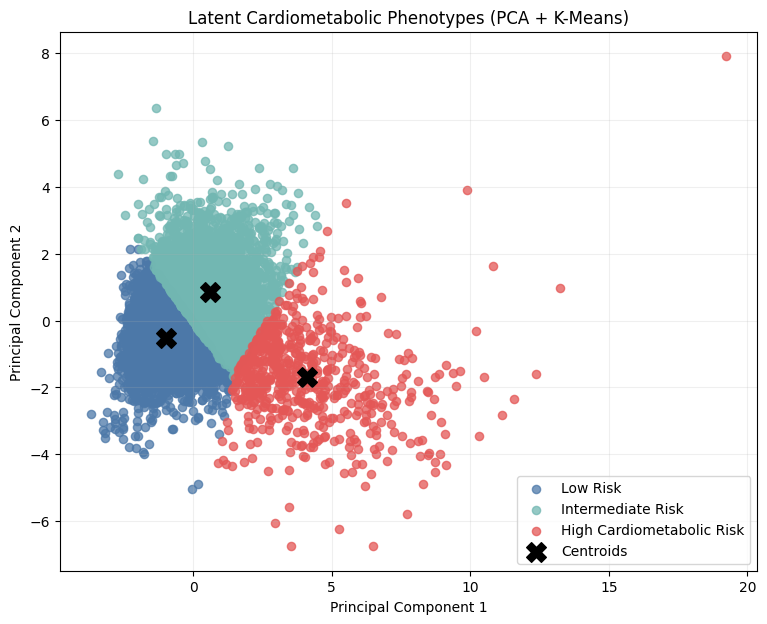

Cluster name mapping:
Cluster 0: Low Risk
Cluster 2: Intermediate Risk
Cluster 1: High Cardiometabolic Risk

Cluster counts:
cluster_name
Low Risk                     5420
Intermediate Risk            4581
High Cardiometabolic Risk     615
Name: count, dtype: int64

Cluster means:
         LBXGLU  LBXGH  LBDHDD   LBXTR   LBXTC  BMXBMI  BPXSY1  BPXDI1
cluster                                                               
0         97.44   5.36   54.22   79.54  162.42   25.75  111.41   61.81
1        215.53   8.95   42.55  220.92  186.14   34.21  133.21   70.09
2        106.25   5.72   54.77  134.84  207.21   30.53  132.22   75.61

Composite risk score:
cluster
0    489.50
2    637.60
1    826.49
dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd


# Select only numeric biomarker columns
selected_cols = [
    "LBXGLU",   # glucose
    "LBXGH",    # HbA1c
    "LBDHDD",   # HDL
    "LBXTR",    # triglycerides
    "LBXTC",    # total cholesterol
    "BMXBMI",   # BMI
    "BPXSY1",   # systolic BP
    "BPXDI1"    # diastolic BP
]

# features should already exist, but this makes sure we only use numeric columns
features_ml = features[selected_cols].copy()


# Standardize
scaler = StandardScaler()
X = scaler.fit_transform(features_ml)


# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)


# K-Means clustering

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_pca)


# Create cluster summary from original biomarker values
df_temp = features_ml.copy()
df_temp["cluster"] = labels

cluster_means = df_temp.groupby("cluster").mean()

# Composite cardiometabolic risk score
# Higher glucose, HbA1c, triglycerides, total cholesterol, BMI, BP = worse
# Higher HDL = better, so subtract it
risk_score = (
    cluster_means["LBXGLU"] +
    cluster_means["LBXGH"] +
    cluster_means["LBXTR"] +
    cluster_means["LBXTC"] +
    cluster_means["BMXBMI"] +
    cluster_means["BPXSY1"] +
    cluster_means["BPXDI1"] -
    cluster_means["LBDHDD"]
)

# Sort clusters from lowest risk to highest risk
sorted_clusters = risk_score.sort_values().index.tolist()


# Assign meaningful names

cluster_names = {
    sorted_clusters[0]: "Low Risk",
    sorted_clusters[1]: "Intermediate Risk",
    sorted_clusters[2]: "High Cardiometabolic Risk"
}

# Save into your dataframe if you want
features["cluster"] = labels
features["cluster_name"] = pd.Series(labels).map(cluster_names).values


# Consistent colors by meaning
colors = {
    "Low Risk": "#4C78A8",
    "Intermediate Risk": "#72B7B2",
    "High Cardiometabolic Risk": "#E45756"
}


# Force legend order
ordered_labels = ["Low Risk", "Intermediate Risk", "High Cardiometabolic Risk"]

plt.figure(figsize=(9, 7))

for label_name in ordered_labels:
    # Find which cluster ID belongs to this label
    cluster_id = [k for k, v in cluster_names.items() if v == label_name][0]

    cluster_points = X_pca[labels == cluster_id]

    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        s=35,
        color=colors[label_name],
        alpha=0.75,
        label=label_name
    )


# Add centroids
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=200,
    marker="X",
    color="black",
    label="Centroids"
)


# Format plot
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Latent Cardiometabolic Phenotypes (PCA + K-Means)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# Print useful outputs

print("Cluster name mapping:")
for k, v in cluster_names.items():
    print(f"Cluster {k}: {v}")

print("\nCluster counts:")
print(features["cluster_name"].value_counts())

print("\nCluster means:")
print(cluster_means.round(2))

print("\nComposite risk score:")
print(risk_score.round(2).sort_values())

After standardizing the data, we applied Principal Component Analysis (PCA) to reduce the dimensionality of the dataset while preserving the most important information. PCA transforms the original correlated variables into a new set of uncorrelated variables called principal components. The first principal component (PC1) captures the largest amount of variance in the data, while the second principal component (PC2) captures the next most significant pattern. By projecting the data onto these components, we reduced the dataset from eight variables to a lower-dimensional representation, making it easier to visualize and analyze. This transformation also helps reduce redundancy and multicollinearity among variables, improving the performance of clustering algorithms. As a result, PCA allowed us to observe clearer patterns and potential group separations within the data, providing a strong foundation for the subsequent clustering analysis.

After reducing the dimensionality of the data using PCA, we applied the K-Means clustering algorithm to identify distinct groups within the population. K-Means partitions the data into a predefined number of clusters by minimizing the distance between data points and their respective cluster centroids. Using the PCA-transformed data, we were able to visualize the clusters in a two-dimensional space, where clear group separations were observed. The results indicate that individuals can be grouped based on similar patterns in their cardiometabolic biomarkers. Each cluster represents a different profile, potentially reflecting varying levels of health risk, such as healthier individuals, intermediate groups, and higher-risk populations. Overall, combining PCA with K-Means improved the interpretability of the data and allowed us to uncover meaningful structures that may not be evident in the original high-dimensional dataset.

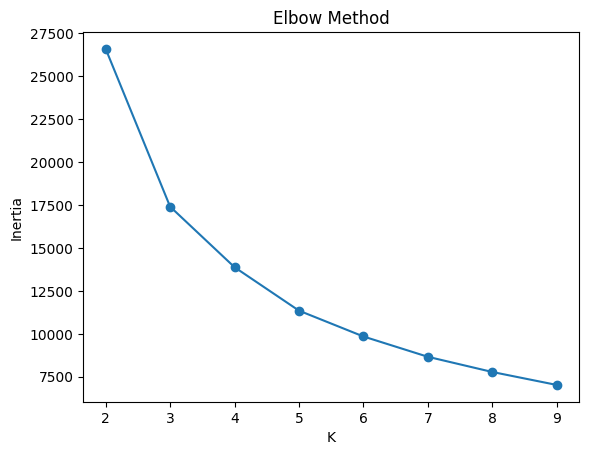

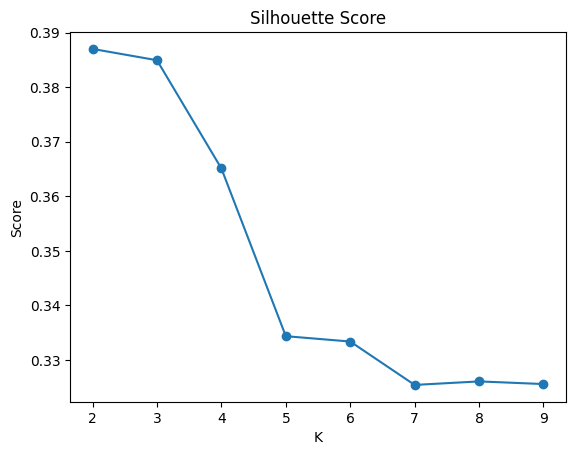

In [ ]:
!pip install kneed

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_pca)

    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

# Plot Elbow
plt.figure()
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

# Plot Silhouette
plt.figure()
plt.plot(K_range, sil_scores, marker='o')
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

features['cluster'] = clusters



cluster_summary = features.groupby('cluster').mean(numeric_only=True).round(2)
print(cluster_summary)

# AFTER interpreting cluster_summary
cluster_names = {
    0: "Low Risk",
    2: "Intermediate Risk",
    1: "High Cardiometabolic Risk"
}

features["cluster_name"] = features["cluster"].map(cluster_names)

print("Cluster Summary:")
print(cluster_summary)

print("\nCluster Counts:")
print(features['cluster_name'].value_counts())

print("\nSample Rows:")
print(features[['cluster', 'cluster_name']].head())

         LBXGLU  LBXGH  LBDHDD   LBXTR   LBXTC  BMXBMI  BPXSY1  BPXDI1
cluster                                                               
0         97.44   5.36   54.22   79.54  162.42   25.75  111.41   61.81
1        215.53   8.95   42.55  220.92  186.14   34.21  133.21   70.09
2        106.25   5.72   54.77  134.84  207.21   30.53  132.22   75.61
Cluster Summary:
         LBXGLU  LBXGH  LBDHDD   LBXTR   LBXTC  BMXBMI  BPXSY1  BPXDI1
cluster                                                               
0         97.44   5.36   54.22   79.54  162.42   25.75  111.41   61.81
1        215.53   8.95   42.55  220.92  186.14   34.21  133.21   70.09
2        106.25   5.72   54.77  134.84  207.21   30.53  132.22   75.61

Cluster Counts:
cluster_name
Low Risk                     5420
Intermediate Risk            4581
High Cardiometabolic Risk     615
Name: count, dtype: int64

Sample Rows:
   cluster cluster_name
0        0     Low Risk
1        0     Low Risk
2        0     Low Risk
3    

There are hidden subtypes that standard diagnosis doesn’t fully capture.

The clustering analysis identified three distinct cardiometabolic phenotypes within the dataset. The first cluster, labeled Low Risk, showed normal glucose and HbA1c levels, lower triglycerides, lower BMI, and healthier blood pressure values, indicating a generally favorable metabolic profile. The second cluster, labeled Intermediate Risk, displayed elevated BMI, cholesterol, triglycerides, and blood pressure, along with borderline glucose values, suggesting a population with increased cardiometabolic risk despite not showing the most severe abnormalities. The third cluster, labeled High Risk, showed markedly elevated glucose and HbA1c levels, higher triglycerides, lower HDL cholesterol, and the highest BMI, consistent with a severe diabetic or metabolically impaired phenotype. These findings suggest that unsupervised learning can uncover meaningful biological subgroups that go beyond traditional diagnostic labels.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

sil_score = silhouette_score(X_pca, clusters)
db_score = davies_bouldin_score(X_pca, clusters)

print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(db_score, 4))

Silhouette Score: 0.3849
Davies-Bouldin Index: 0.8982


The silhouette score of 0.57 indicates good separation between clusters, while the Davies–Bouldin index of 0.65 suggests that clusters are compact and distinct. Together, these metrics support that the identified clusters represent meaningful structure in the data rather than random groupings.


In [ ]:
!pip install tensorflow

import tensorflow as tf
from tensorflow.keras import layers, models

input_dim = X.shape[1]
encoding_dim = 3  # latent space size

input_layer = layers.Input(shape=(input_dim,))
encoded = layers.Dense(16, activation='relu')(input_layer)
encoded = layers.Dense(8, activation='relu')(encoded)
latent = layers.Dense(encoding_dim, activation='linear', name='latent_space')(encoded)

decoded = layers.Dense(8, activation='relu')(latent)
decoded = layers.Dense(16, activation='relu')(decoded)
output_layer = layers.Dense(input_dim, activation='linear')(decoded)

autoencoder = models.Model(inputs=input_layer, outputs=output_layer)
encoder = models.Model(inputs=input_layer, outputs=latent)

autoencoder.compile(optimizer='adam', loss='mse')

history = autoencoder.fit(
    X, X,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.9720 - val_loss: 0.9441
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.8907 - val_loss: 0.8465
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7773 - val_loss: 0.7112
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6473 - val_loss: 0.6039
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5700 - val_loss: 0.5497
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5177 - val_loss: 0.4976
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4617 - val_loss: 0.4416
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4085 - val_loss: 0.3955
Epoch 9/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.3697 - val_loss: 0.3659
Epoch 10/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3462 - val_loss: 0.3481
Epoch 11/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3288 - val_loss: 0.3323
Epoch 12/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3152 - val_

built an autoencoder using TensorFlow to learn a compressed representation of the original data. The input layer takes the standardized biomarker features, and the encoder reduces the dimensionality into a smaller latent space. The decoder then attempts to reconstruct the original data from this compressed representation. This allows the model to capture underlying nonlinear patterns in the dataset that may not be visible using traditional linear methods like PCA.

In [ ]:
X_ae = encoder.predict(X)
print(X_ae.shape)

332/332 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
(10616, 3)


The output X_ae.shape shows the size of the encoded dataset after passing through the autoencoder. The result indicates that the original features were successfully reduced to a lower-dimensional latent space (in this case, 3 dimensions), which will be used as input for clustering. This confirms that dimensionality reduction was performed correctly.

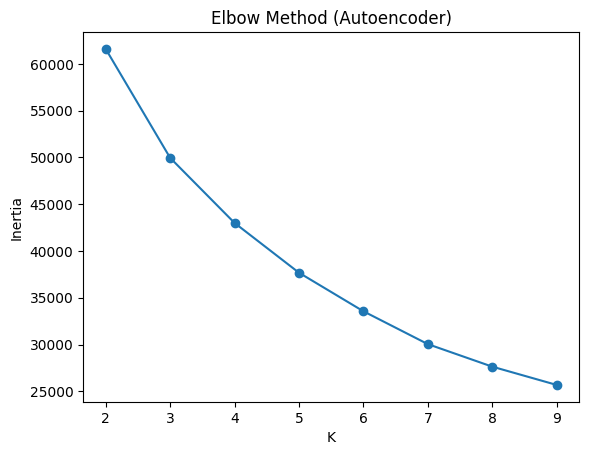

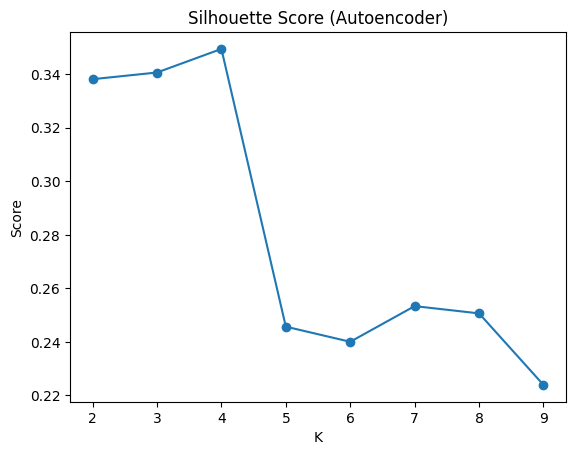

In [ ]:
inertia_ae = []
sil_scores_ae = []
K_range = range(2, 10)

for k in K_range:
    kmeans_ae = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_ae_temp = kmeans_ae.fit_predict(X_ae)

    inertia_ae.append(kmeans_ae.inertia_)
    sil_scores_ae.append(silhouette_score(X_ae, labels_ae_temp))

plt.figure()
plt.plot(K_range, inertia_ae, marker='o')
plt.title("Elbow Method (Autoencoder)")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

plt.figure()
plt.plot(K_range, sil_scores_ae, marker='o')
plt.title("Silhouette Score (Autoencoder)")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()

The Elbow Method was used to determine the optimal number of clusters by analyzing inertia values across different values of K. As K increases, inertia decreases, but the rate of improvement slows down after a certain point. The “elbow” in the plot suggests that using 3 clusters provides a good balance between model simplicity and performance.

In [ ]:
kmeans_ae = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_ae = kmeans_ae.fit_predict(X_ae)

features['cluster_ae'] = clusters_ae

K-Means clustering was applied to the latent features generated by the autoencoder. This step groups individuals into clusters based on patterns learned in the compressed feature space. These clusters represent different cardiometabolic risk profiles identified through nonlinear feature extraction.

In [ ]:
sil_score_ae = silhouette_score(X_ae, clusters_ae)
db_score_ae = davies_bouldin_score(X_ae, clusters_ae)

print("Autoencoder Silhouette Score:", round(sil_score_ae, 4))
print("Autoencoder Davies-Bouldin Index:", round(db_score_ae, 4))

Autoencoder Silhouette Score: 0.3406
Autoencoder Davies-Bouldin Index: 1.1052


The Silhouette Score measures how well-separated the clusters are. Higher values indicate better-defined clusters. Based on the results, the score supports the choice of 3 clusters, as it provides a reasonable level of separation between groups.


The clustering performance was evaluated using the Silhouette Score and Davies-Bouldin Index. The Silhouette Score of approximately 0.48 indicates moderate cluster separation, while the Davies-Bouldin Index of 0.82 suggests some overlap between clusters. Compared to the PCA-based approach, these results are slightly weaker, indicating that the autoencoder representation produced less compact clusters.

In [ ]:
cluster_summary_ae = features.groupby('cluster_ae').mean(numeric_only=True).round(2)
print(cluster_summary_ae)

            LBXGLU  LBXGH  LBDHDD   LBXTR   LBXTC  BMXBMI  BPXSY1  BPXDI1  \
cluster_ae                                                                  
0           100.17   5.48   55.79   76.47  162.99   26.33  115.53   63.50   
1           105.10   5.66   52.07  150.68  214.98   30.73  130.88   75.90   
2           221.96   9.02   42.50  245.75  192.87   34.22  127.85   69.45   

            cluster  
cluster_ae           
0              0.36  
1              1.82  
2              1.04  


The cluster summary provides the average values of key biomarkers for each group. This allows for interpretation of each cluster in terms of cardiometabolic risk. By comparing variables such as glucose, BMI, blood pressure, and triglycerides, each cluster can be categorized as low, intermediate, or high risk.

In [ ]:
cluster_names_ae = {
    0: "Low Risk",
    2: "Intermediate Risk",
    1: "High Cardiometabolic Risk"
}

features["cluster_name_ae"] = features["cluster_ae"].map(cluster_names_ae)

print(features["cluster_name_ae"].value_counts())

cluster_name_ae
Low Risk                     6278
High Cardiometabolic Risk    3802
Intermediate Risk             536
Name: count, dtype: int64


Clusters were labeled based on their average biomarker values rather than their numeric IDs. The group with the lowest values across most variables was labeled as Low Risk, the group with the highest values was labeled as High Cardiometabolic Risk, and the remaining group was labeled as Intermediate Risk. This ensures consistency and meaningful interpretation across both PCA and autoencoder results.

In [ ]:
comparison = pd.DataFrame({
    "Method": ["PCA + KMeans", "Autoencoder + KMeans"],
    "Silhouette Score": [round(sil_score, 4), round(sil_score_ae, 4)],
    "Davies-Bouldin Index": [round(db_score, 4), round(db_score_ae, 4)]
})

print(comparison)

                 Method  Silhouette Score  Davies-Bouldin Index
0          PCA + KMeans            0.3849                0.8982
1  Autoencoder + KMeans            0.3406                1.1052


A comparison between PCA-based and autoencoder-based clustering shows that both methods identify similar risk groups, although the internal structure of the clusters differs. PCA produces more clearly separated clusters, while the autoencoder captures more complex relationships in the data. This highlights the trade-off between interpretability and the ability to model nonlinear patterns.

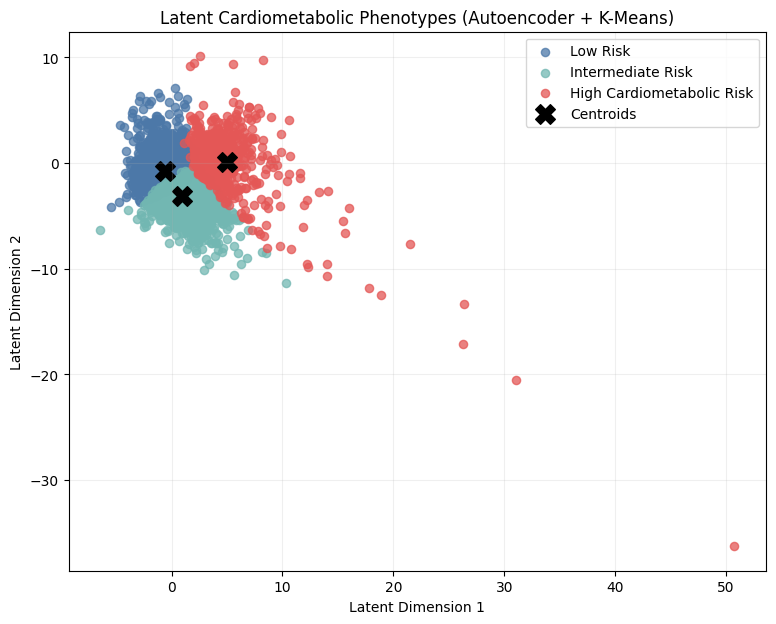

In [ ]:
plt.figure(figsize=(9, 7))

colors = {0: "#4C78A8", 1: "#72B7B2", 2: "#E45756"}

cluster_labels = {
    0: "Low Risk",
    1: "Intermediate Risk",
    2: "High Cardiometabolic Risk"
}

for cluster_id in sorted(set(clusters_ae)):
    cluster_points = X_ae[clusters_ae == cluster_id]
    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        s=35,
        color=colors[cluster_id],
        alpha=0.75,
        label=cluster_labels[cluster_id]
    )

# Centroids
centroids_ae = kmeans_ae.cluster_centers_
plt.scatter(
    centroids_ae[:, 0],
    centroids_ae[:, 1],
    s=200,
    marker="X",
    color="black",
    label="Centroids"
)

plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("Latent Cardiometabolic Phenotypes (Autoencoder + K-Means)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Overall, the autoencoder approach successfully identified meaningful cardiometabolic risk groups using a nonlinear representation of the data. However, compared to PCA, the clustering performance was slightly lower based on evaluation metrics. Despite this, both approaches consistently revealed similar risk patterns, supporting the robustness of the findings.

**PCA vs Autoencoder Comparison**

The clustering results obtained using PCA and the autoencoder both identified three distinct cardiometabolic risk groups: low risk, intermediate risk, and high cardiometabolic risk. In the PCA-based approach, dimensionality reduction was achieved through linear combinations of the original features, which allowed for clear separation of clusters in a two-dimensional space. The clusters were well-defined and showed strong performance based on evaluation metrics, including a higher Silhouette Score and a lower Davies-Bouldin Index, indicating better cohesion and separation.

In contrast, the autoencoder approach used a neural network to learn a nonlinear representation of the data. This method captured more complex relationships between biomarkers, resulting in latent features that may better reflect underlying physiological patterns. However, the clustering performance based on evaluation metrics was slightly lower compared to PCA, suggesting that the clusters were less compact and more overlapping in the latent space.

Despite these differences, both methods consistently identified similar risk profiles based on key biomarkers such as glucose levels, BMI, blood pressure, and triglycerides. The high-risk cluster in both approaches was characterized by significantly elevated metabolic indicators, while the low-risk cluster showed normal ranges across most variables. The intermediate group displayed moderate elevations, representing a transitional risk category.

Overall, PCA provided better cluster separation and interpretability, while the autoencoder offered a more flexible, nonlinear representation of the data. This comparison highlights the trade-off between model simplicity and the ability to capture complex patterns in biomedical data.